In [1]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,roc_curve, auc,mean_squared_error,recall_score,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV,HalvingGridSearchCV
from tqdm import tqdm
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.calibration import calibration_curve
import xgboost as xgb
import os
import shap

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



In [2]:
import warnings
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
import shap, xgboost
print(shap.__version__, xgboost.__version__)

0.54.1 3.4.1


In [4]:
feature_PATH = "../data/processed/features/feature_cols.csv"
feature_cols = pd.read_csv(feature_PATH)["feature"].tolist()

response_PATH = "../data/processed/response_cols/response_cols.csv"
response_cols = pd.read_csv(response_PATH)["response"].tolist()

train_data = pd.DataFrame() 
train_PATH = f"../data/processed/train/train_data.parquet"
train_data = pd.concat([train_data, pd.read_parquet(train_PATH)])

test_data = pd.DataFrame() 
test_PATH = f"../data/processed/test/test_data.parquet"
test_data = pd.concat([test_data , pd.read_parquet(test_PATH)])

In [5]:
common = train_data.columns.intersection(test_data.columns)
object_cols = train_data[common].select_dtypes(include=["object"]).columns

for col in object_cols:
    cats = pd.concat([train_data[col], test_data[col]]).dropna().unique()
    dtype = pd.CategoricalDtype(categories=cats)
    train_data[col] = train_data[col].astype(dtype)
    test_data[col] = test_data[col].astype(dtype)

In [6]:
attr = "wrong_call"

In [7]:
train_features, test_features = train_data[feature_cols].drop(columns=["pitcher","batter"]) , test_data[feature_cols].drop(columns=["pitcher","batter"])
train_response, test_response = train_data[response_cols][attr] , test_data[response_cols][attr]

In [8]:
umps = list(pd.concat([train_features, test_features])["hp_official_id"].unique())


# 1.1 create umpire features

In [9]:
def create_umpire_features(
    train_data,
    test_data,
    date_col="game_date",
    umpire_col="hp_official_id",
    target_col="wrong_call",
    warmup_fraction=0.20,
    n_clusters=3,
    prior_strength=50
):

    train = train_data.copy()
    test = test_data.copy()

# prep

    train[date_col] = pd.to_datetime(train[date_col])
    test[date_col] = pd.to_datetime(test[date_col])

    # if train[date_col].isna().any() or test[date_col].isna().any():
    #     raise ValueError("Missing dates must be handled first.")

    train = train.sort_values(date_col)

    dates = np.sort(train[date_col].unique())

    if len(dates) < 2:
        raise ValueError("Not enough training dates.")

    cutoff_idx = max(
        0, int(len(dates) * warmup_fraction) - 1
    )

    cutoff_date = dates[cutoff_idx]

    # Initial historical period
    warmup = train[
        train[date_col] <= cutoff_date
    ].copy()

    # Remaining observations used for model training
    remaining = train[
        train[date_col] > cutoff_date
    ].copy()

    # if remaining.empty:
    #     raise ValueError("No training observations remain after warmup.")

    # print("Warmup dates:", len(warmup[date_col].unique()))
    # print("Warmup observations:", len(warmup))
    # print("Model training observations:", len(remaining))
    # print("Historical cutoff:", cutoff_date)

    # initial profiles

    global_rate = warmup[target_col].mean()

    umpire_profiles = (
        warmup
        .dropna(subset=[umpire_col])
        .groupby(umpire_col)
        .agg(
            historical_wrong_calls=(target_col, "sum"),
            historical_calls=(target_col, "count")
        )
    )

    umpire_profiles["disagreement_rate"] = (
        umpire_profiles["historical_wrong_calls"]
        / umpire_profiles["historical_calls"]
    )

    # smoothing
    umpire_profiles["smoothed_disagreement_rate"] = (
        umpire_profiles["historical_wrong_calls"]
        + prior_strength * global_rate
    ) / (
        umpire_profiles["historical_calls"]
        + prior_strength
    )

    umpire_profiles["log_call_volume"] = np.log1p(
        umpire_profiles["historical_calls"]
    )

    #fit k means

    cluster_features = [
        "smoothed_disagreement_rate",
        "log_call_volume"
    ]

    # if len(umpire_profiles) == 0:
    #     raise ValueError("No umpires found in the warmup period.")

    scaler = StandardScaler()

    X_profiles = scaler.fit_transform(
        umpire_profiles[cluster_features]
    )

    actual_clusters = min(
        n_clusters, len(umpire_profiles)
    )

    if actual_clusters >= 2:

        kmeans = KMeans(
            n_clusters=actual_clusters,
            random_state=6740,
            n_init=20
        )

        umpire_profiles["umpire_cluster"] = (
            kmeans.fit_predict(X_profiles)
        )

    else:
        kmeans = None
        umpire_profiles["umpire_cluster"] = 0

    # print("K-Means clusters:", actual_clusters)

    # historical counts

    history = {}

    for ump, row in umpire_profiles.iterrows():

        history[ump] = [
            row["historical_wrong_calls"],
            row["historical_calls"]
        ]

    # make features

    def get_profile(ump):

        if pd.isna(ump) or ump not in history:
            wrong_calls, total_calls = 0, 0
        else:
            wrong_calls, total_calls = history[ump]

        rate = (
            wrong_calls + prior_strength * global_rate
        ) / (
            total_calls + prior_strength
        )

        return rate, total_calls

    def get_cluster(rate, total_calls):

        if total_calls == 0:
            return -1

        if kmeans is None:
            return 0

        profile = pd.DataFrame(
            [[rate, np.log1p(total_calls)]],
            columns=cluster_features
        )

        scaled = scaler.transform(profile)

        return int(kmeans.predict(scaled)[0])

    def make_features(df):

        records = []

        for idx, row in df.iterrows():

            ump = row[umpire_col]

            rate, volume = get_profile(ump)

            cluster = get_cluster(rate, volume)

            records.append({
                "index": idx,
                "umpire_hist_disagreement_rate": rate,
                "umpire_hist_call_volume": volume,
                "umpire_cluster": cluster
            })

        return (
            pd.DataFrame(records)
            .set_index("index")
        )

    # training features

    train_feature_parts = []

    for date, day_data in remaining.groupby(
        date_col, sort=True
    ):

        # prev dates
        day_features = make_features(day_data)

        train_feature_parts.append(day_features)

        # update
        daily_stats = (
            day_data
            .dropna(subset=[umpire_col])
            .groupby(umpire_col)[target_col]
            .agg(["sum", "count"])
        )

        for ump, stats in daily_stats.iterrows():

            if ump not in history:
                history[ump] = [0, 0]

            history[ump][0] += stats["sum"]
            history[ump][1] += stats["count"]

    train_umpire_features = pd.concat(
        train_feature_parts
    )

    # make test features

    test_umpire_features = make_features(test)

    # Consistent cat levels
    cluster_categories = list(
        range(actual_clusters)
    ) + [-1]

    train_umpire_features["umpire_cluster"] = pd.Categorical(
        train_umpire_features["umpire_cluster"],
        categories=cluster_categories
    )

    test_umpire_features["umpire_cluster"] = pd.Categorical(
        test_umpire_features["umpire_cluster"],
        categories=cluster_categories
    )
    #features/ model data

    return (
        train_umpire_features,
        test_umpire_features,
        remaining,
        umpire_profiles,
        kmeans,
        scaler
    )

In [10]:

attr = "wrong_call"

# make features

(
    train_umpire_features,
    test_umpire_features,
    train_model_data,
    umpire_profiles,
    kmeans,
    scaler
) = create_umpire_features(
    train_data,
    test_data,
    date_col="game_date",
    umpire_col="hp_official_id",
    target_col="wrong_call",
    warmup_fraction=0.20,
    n_clusters=3,
    prior_strength=50
)

# prep original features

train_features = train_model_data[feature_cols].drop(
    columns=["pitcher", "batter"]
)

test_features = test_data[feature_cols].drop(
    columns=["pitcher", "batter"]
)

# add in umpire features

umpire_feature_cols = [
    "umpire_hist_disagreement_rate",
    "umpire_hist_call_volume",
    "umpire_cluster"
]

train_features = train_features.join(
    train_umpire_features[umpire_feature_cols]
)

test_features = test_features.join(
    test_umpire_features[umpire_feature_cols]
)

# response
train_response = train_model_data[response_cols][attr]

test_response = test_data[response_cols][attr]

# cross validaton

cv = TimeSeriesSplit(n_splits=5)

print("Training shape:", train_features.shape)
print("Testing shape:", test_features.shape)

print("Training response:", train_response.shape)
print("Testing response:", test_response.shape)

print("Added features:", umpire_feature_cols)


Training shape: (886197, 25)
Testing shape: (375142, 25)
Training response: (886197,)
Testing response: (375142,)
Added features: ['umpire_hist_disagreement_rate', 'umpire_hist_call_volume', 'umpire_cluster']


# Make a elbow plot to determine number of clusters - then adjust the above cluster count, based on that elbow plot results

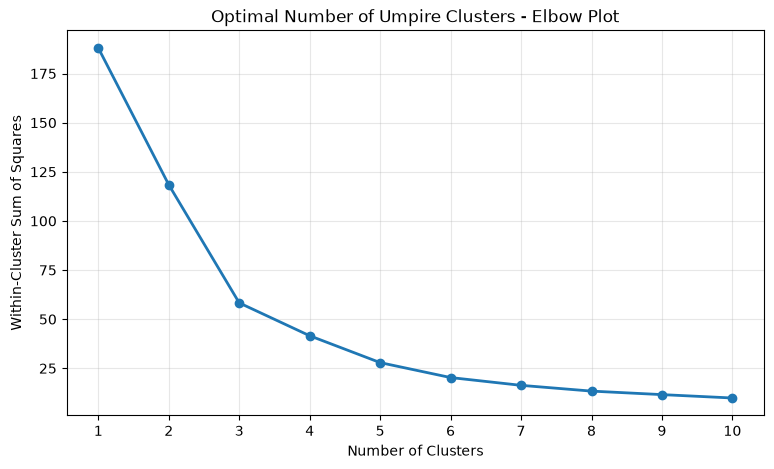

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


cluster_features = [
    "smoothed_disagreement_rate",
    "log_call_volume"
]

X = umpire_profiles[cluster_features].dropna()


elbow_scaler = StandardScaler()
X_scaled = elbow_scaler.fit_transform(X)

# k value loops

max_k = min(10, len(X))

k_values = range(1, max_k + 1)
inertias = []

for k in k_values:

    km = KMeans(
        n_clusters=k,
        random_state=6740,
        n_init=20
    )

    km.fit(X_scaled)

    inertias.append(km.inertia_)

# plot

plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertias,
    marker="o",
    linewidth=2
)

plt.xlabel("Number of Clusters")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("Optimal Number of Umpire Clusters - Elbow Plot")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

In [12]:
# Inspect initial K-Means profiles
cluster_summary = umpire_profiles.copy()

cluster_summary["cluster"] = kmeans.labels_ if kmeans else 0

print(
    cluster_summary.groupby("cluster").agg(
        umpire_count=("historical_calls", "count"),
        avg_disagreement=("disagreement_rate", "mean"),
        avg_calls=("historical_calls", "mean")
    )
)

         umpire_count  avg_disagreement    avg_calls
cluster                                             
0                  30          0.108436  2431.900000
1                  58          0.089741  2676.379310
2                   6          0.093965   476.666667


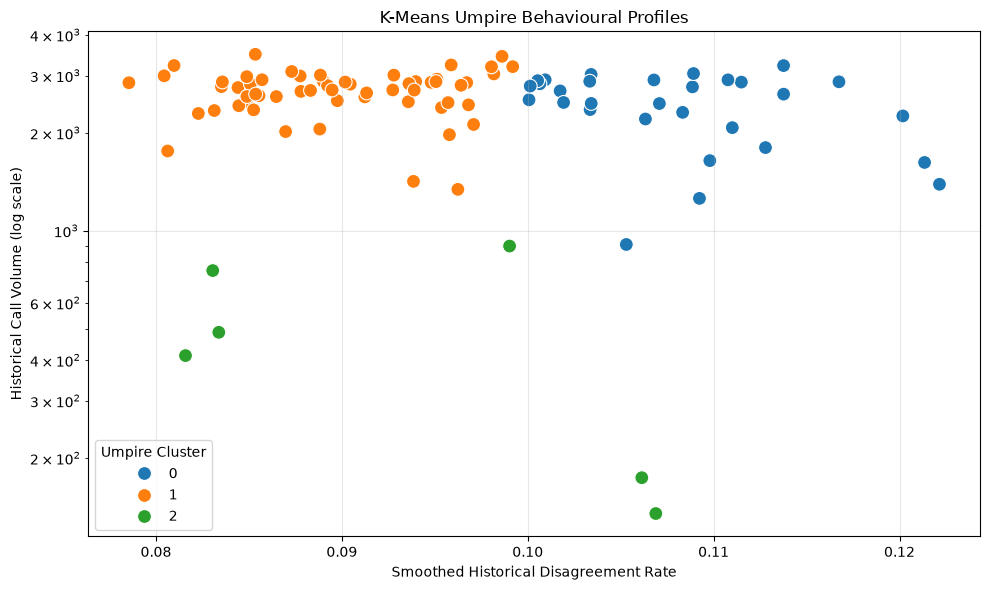

In [13]:
# make k means plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=umpire_profiles,
    x="smoothed_disagreement_rate",
    y="historical_calls",
    hue="umpire_cluster",
    palette="tab10",
    s=100
)

plt.yscale("log")

plt.xlabel("Smoothed Historical Disagreement Rate")
plt.ylabel("Historical Call Volume (log scale)")
plt.title("K-Means Umpire Behavioural Profiles")

plt.legend(title="Umpire Cluster")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
# missing values
print(train_features[umpire_feature_cols].isna().sum())
print(test_features[umpire_feature_cols].isna().sum())

# cluster distribution
print(
    train_features["umpire_cluster"]
    .value_counts(dropna=False)
)

# Check historical call volume
print(
    train_features["umpire_hist_call_volume"]
    .describe()
)

# umpire profiles
display(umpire_profiles.head())

#cluster characteristics
display(
    umpire_profiles.groupby("umpire_cluster").agg(
        umpire_count=("historical_calls", "count"),
        avg_disagreement=(
            "smoothed_disagreement_rate", "mean"
        ),
        avg_call_volume=("historical_calls", "mean")
    )
)

umpire_hist_disagreement_rate    0
umpire_hist_call_volume          0
umpire_cluster                   0
dtype: int64
umpire_hist_disagreement_rate    0
umpire_hist_call_volume          0
umpire_cluster                   0
dtype: int64
umpire_cluster
 1    725257
 0    143517
 2     14189
-1      3234
Name: count, dtype: int64
count    886197.000000
mean       7270.997888
std        3374.256199
min           0.000000
25%        4509.000000
50%        7072.000000
75%       10000.000000
max       14912.000000
Name: umpire_hist_call_volume, dtype: float64


,historical_wrong_calls,historical_calls,disagreement_rate,smoothed_disagreement_rate,log_call_volume,umpire_cluster
hp_official_id,,,,,,
427013,256,2880,0.088889,0.089002,7.965893,1
427019,320,2863,0.111771,0.111491,7.959975,0
427044,300,2629,0.114112,0.113764,7.874739,0
427053,270,2874,0.093946,0.093972,7.963808,1
427093,294,2910,0.101031,0.100937,7.976252,0


,umpire_count,avg_disagreement,avg_call_volume
umpire_cluster,,,
0,30,0.108139,2431.900000
1,58,0.089849,2676.379310
2,6,0.093345,476.666667


In [15]:
# umpire_profiles.to_csv(
#     "../results/stats/umpire_profiles.csv",
#     index=False
# )

# cluster_summary.to_csv(
#     "../results/stats/umpire_cluster_summary.csv"
# )

In [16]:
train_features.head()

,release_speed,release_spin_rate,pitch_cat,balls,strikes,inning,outs_when_up,inning_topbot,stand,p_throws,...,pitcher_days_since_prev_game,hp_official_id,count,High,Low,Inside,Outside,umpire_hist_disagreement_rate,umpire_hist_call_volume,umpire_cluster
206436,90.8,2122.0,Fastball,2,2,1,1,Top,R,R,...,6.0,427248,2-2,True,False,False,False,0.100535,2892.0,0
206444,95.8,2418.0,Fastball,0,0,10,1,Bot,R,R,...,2.0,427344,0-0,False,False,False,False,0.108918,3042.0,0
206443,88.7,2438.0,Fastball,0,2,10,1,Bot,R,R,...,2.0,427344,0-2,False,False,False,True,0.108918,3042.0,0
206442,86.7,1812.0,Fastball,0,0,1,0,Top,L,R,...,6.0,427248,0-0,False,False,False,False,0.100535,2892.0,0
206441,89.9,2011.0,Fastball,0,1,1,0,Top,L,R,...,6.0,427248,0-1,False,False,False,True,0.100535,2892.0,0


# xgboost

In [17]:
cv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    random_state=6740,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    enable_categorical=True,
    n_jobs=1,
    device = "cuda",
    scale_pos_weight=100 
)

pipe = Pipeline(steps=[("xgb", xgb_model)])

param_grid = {
"xgb__learning_rate":    [ 0.065 , 0.075],
"xgb__max_depth":        [7, 10],
"xgb__min_child_weight": [65, 70,],
"xgb__reg_lambda":       [20, 25],
}

search = HalvingGridSearchCV(
    pipe, param_grid,
    cv=cv,
    scoring="average_precision",
    n_jobs=4,
    verbose=2,
    error_score="raise",
    factor=3,
    resource="xgb__n_estimators",
    max_resources=550,
    min_resources="exhaust"
)


search.fit(train_features, train_response)

print("Best params:", search.best_params_)
print("Best CV PR-AUC:", search.best_score_)
print("Final n_estimators:", search.best_estimator_.named_steps["xgb"].n_estimators)

n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 61
max_resources_: 550
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 16
n_resources: 61
Fitting 5 folds for each of 16 candidates, totalling 80 fits


/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:24] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:24] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:24] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:24] WARNING: /Users/runner/work/xgboost/xgboost

[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=65, xgb__n_estimators=61, xgb__reg_lambda=20; total time=   0.8s
[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=65, xgb__n_estimators=61, xgb__reg_lambda=20; total time=   1.5s


/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:25] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:25] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=65, xgb__n_estimators=61, xgb__reg_lambda=20; total time=   2.3s
[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=65, xgb__n_estimators=61, xgb__reg_lambda=25; total time=   1.0s


/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:27] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)
/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:49:27] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


... (149 outputs left out)

/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:52:12] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=70, xgb__n_estimators=549, xgb__reg_lambda=20; total time=  13.9s


/opt/anaconda3/lib/python3.12/site-packages/xgboost/training.py:200: UserWarning: [18:52:22] WARNING: /Users/runner/work/xgboost/xgboost/src/context.cc:218: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  bst.update(dtrain, iteration=i, fobj=obj)


[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=65, xgb__n_estimators=549, xgb__reg_lambda=20; total time=  31.9s
[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=70, xgb__n_estimators=549, xgb__reg_lambda=20; total time=  20.3s
[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=70, xgb__n_estimators=549, xgb__reg_lambda=20; total time=  23.9s
[CV] END xgb__learning_rate=0.065, xgb__max_depth=7, xgb__min_child_weight=70, xgb__n_estimators=549, xgb__reg_lambda=20; total time=  25.4s
Best params: {'xgb__learning_rate': 0.065, 'xgb__max_depth': 7, 'xgb__min_child_weight': 65, 'xgb__reg_lambda': 20, 'xgb__n_estimators': 549}
Best CV PR-AUC: 0.75016694594861
Final n_estimators: 549


In [18]:
final_model = clone(pipe).set_params(**search.best_params_)
final_model.fit(train_features, train_response)

xgb_train_probs = final_model.predict_proba(train_features)[:, 1]
xgb_test_probs  = final_model.predict_proba(test_features)[:, 1]

pr, rc, th = precision_recall_curve(train_response, xgb_train_probs)
thr = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]
# thr = .99
xgb_train_preds = (xgb_train_probs >= thr).astype(int)
xgb_test_preds  = (xgb_test_probs  >= thr).astype(int)

for name, yt, pp, pl in [("Train", train_response, xgb_train_probs, xgb_train_preds),
                         ("Test",  test_response,  xgb_test_probs,  xgb_test_preds)]:
    print(f"XGB {name}: LogLoss {log_loss(yt, pp):.4f} | ROC-AUC {roc_auc_score(yt, pp):.4f} | "
          f"PR-AUC {average_precision_score(yt, pp):.4f} | F1 {f1_score(yt, pl):.4f} | base rate {yt.mean():.3f}")

results = pd.DataFrame({
    'actual':     pd.concat([train_response, test_response]).values,
    'pred_prob':  np.concatenate([xgb_train_probs, xgb_test_probs]),
    'pred_label': np.concatenate([xgb_train_preds, xgb_test_preds]),
    'split':      ['train'] * len(train_response) + ['test'] * len(test_response)})

XGB Train: LogLoss 0.7009 | ROC-AUC 0.9639 | PR-AUC 0.8050 | F1 0.6950 | base rate 0.092
XGB Test: LogLoss 0.7179 | ROC-AUC 0.9395 | PR-AUC 0.7210 | F1 0.6328 | base rate 0.081


In [19]:
matplotlib widget
plt.close("all")
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Wrong call (1)')]:
    ax[0, 0].hist(xgb_test_probs[test_response.values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(wrong call)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC'); ax[0, 1].legend()

for yt, pp, st, lbl in [(train_response, xgb_train_probs, 'g--', 'Train'), (test_response, xgb_test_probs, 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(test_response.mean(), color='black', linestyle=':', linewidth=1.5, label='Base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall'); ax[1, 0].legend()

# fp, mp = calibration_curve(test_response, xgb_test_probs, n_bins=10, strategy='quantile')
# ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='XGB (test)')
# ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
# ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction wrong', title='Calibration (test)')
# ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Diagnostics.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pl, ttl in [(ax[0], train_response, xgb_train_preds, 'Train'), (ax[1], test_response, xgb_test_preds, 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pl, ax=a, colorbar=False, 
    # normalize='true', 
    # values_format='.2f'
    )
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/XGB_WrongCall_Confusion.png", dpi=300)
plt.show()

SyntaxError: invalid syntax (1043965678.py, line 1)

Exception ignored in: <function ResourceTracker.__del__ at 0x10476a0c0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x102f1e0c0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1077ea0c0>
Traceback (most recent call last

In [ ]:
# train_features["attack_zone"].unique()

In [ ]:
from sklearn.metrics import recall_score, precision_score, average_precision_score

for name, X, y in [("train", train_features, train_response), ("test", test_features, test_response)]:
    p = search.best_estimator_.predict_proba(X)[:, 1]
    print(name, "PR-AUC:", round(average_precision_score(y, p), 4))
    for t in [0.25, 0.5, 0.75,.99]:
        pred = p >= t
        print(f"  t={t}: recall={recall_score(y, pred):.3f} precision={precision_score(y, pred):.3f}")

train PR-AUC: 0.8395
  t=0.25: recall=1.000 precision=0.252
  t=0.5: recall=1.000 precision=0.253
  t=0.75: recall=1.000 precision=0.263
  t=0.99: recall=0.515 precision=0.977
test PR-AUC: 0.7217
  t=0.25: recall=1.000 precision=0.217
  t=0.5: recall=0.998 precision=0.217
  t=0.75: recall=0.982 precision=0.223
  t=0.99: recall=0.444 precision=0.922


In [ ]:
OUT_DIR = "../results/raw"
os.makedirs(OUT_DIR, exist_ok=True)

# `results` was already built after the model fit cell; reuse it.
preds_df = results.copy()

preds_path = os.path.join(OUT_DIR, "xgb_predictions_vs_actuals_cluster.csv")
preds_df.to_csv(preds_path, index=False)
print(f"Saved {len(preds_df):,} rows -> {preds_path}")
print(preds_df.head())

Saved 1,492,386 rows -> ../results/raw\xgb_predictions_vs_actuals.csv
   actual  pred_prob  pred_label  split
0       0   0.905673           0  train
1       1   0.987710           1  train
2       0   0.000526           0  train
3       0   0.975038           0  train
4       0   0.000193           0  train


In [ ]:
OUT_DIR = "../results/stats"
os.makedirs(OUT_DIR, exist_ok=True)
def _metric_row(y_true, prob, pred, threshold):
    return {
        "threshold":  threshold,
        "log_loss":   log_loss(y_true, prob),
        "roc_auc":    roc_auc_score(y_true, prob),
        "pr_auc":     average_precision_score(y_true, prob),
        "accuracy":   accuracy_score(y_true, pred),
        "precision":  precision_score(y_true, pred, zero_division=0),
        "recall":     recall_score(y_true, pred, zero_division=0),
        "f1":         f1_score(y_true, pred, zero_division=0),
        "base_rate":  float(np.mean(y_true)),
        "n_rows":     len(y_true),
    }

metrics_df = pd.DataFrame([
    {"split": "train", **_metric_row(train_response, xgb_train_probs, xgb_train_preds, thr)},
    {"split": "test",  **_metric_row(test_response,  xgb_test_probs,  xgb_test_preds,  thr)},
])

metrics_path = os.path.join(OUT_DIR, "xgb_metrics_cluster.csv")
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved metrics -> {metrics_path}")
display(metrics_df)

Saved metrics -> ../results/stats/xgb_metrics_cluster.csv


,split,threshold,log_loss,roc_auc,pr_auc,accuracy,precision,recall,f1,base_rate,n_rows
0,train,0.981459,0.700878,0.963940,0.805015,0.951088,0.812753,0.607082,0.695021,0.091806,886197
1,test,0.981459,0.717897,0.939474,0.720983,0.948643,0.748040,0.548355,0.632819,0.080705,375142


Exception ignored in: <function ResourceTracker.__del__ at 0x111b820c0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10546e0c0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/opt/anaconda3/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10371e0c0>
Traceback (most recent call last

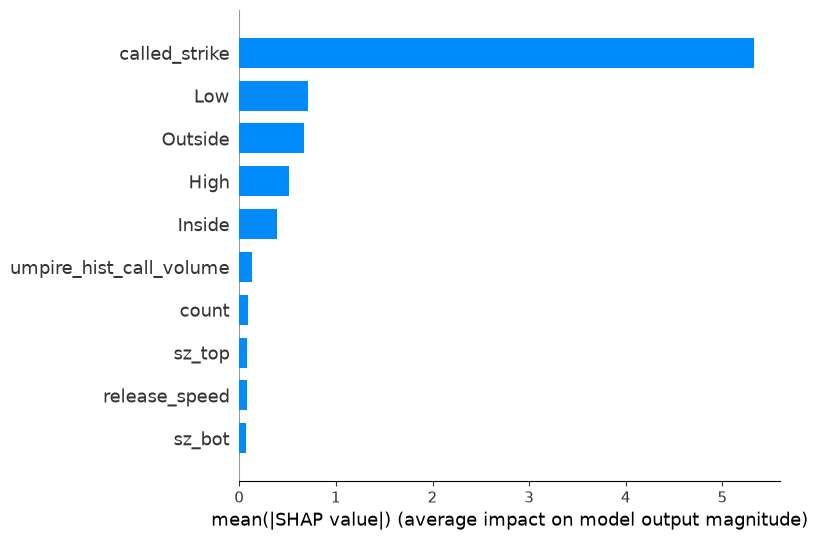

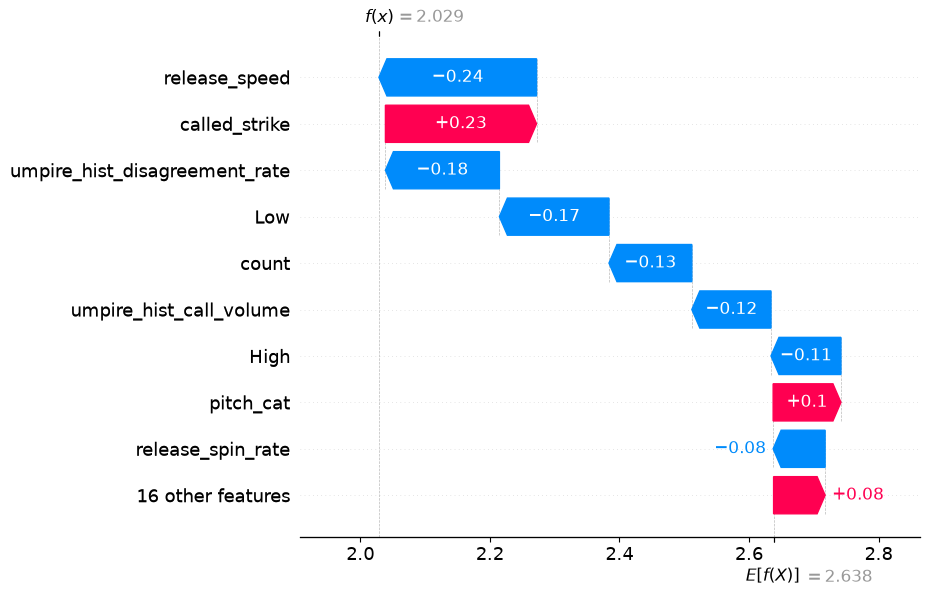

In [ ]:
plt.close("all")
xgb_fitted = final_model.named_steps["xgb"]
booster = xgb_fitted.get_booster()

dtest = xgb.DMatrix(test_features, enable_categorical=True)

shap_raw = booster.predict(dtest, pred_contribs=True)

shap_values = shap_raw[:, :-1]
base_values = shap_raw[:, -1]

shap.summary_plot(
    shap_values,
    features=None,
    feature_names=test_features.columns.tolist(),
    plot_type="bar",
    max_display=10
)

shap_exp = shap.Explanation(
    values=shap_values[25],
    base_values=base_values[25],
    feature_names=test_features.columns.tolist()
)

shap.plots.waterfall(shap_exp)


In [ ]:
xgb_model.save_model("stl_xgboost_cluster.json")
X_combined.to_csv("stl_xgboost_xvals_cluster.csv")

In [ ]:
# test on packaging results

# OUT_DIR = "../results/raw"
# os.makedirs(OUT_DIR, exist_ok=True)

# umpire_feature_cols = [
#     "umpire_hist_disagreement_rate",
#     "umpire_hist_call_volume",
#     "umpire_cluster"
# ]


# train_scored = train_model_data.copy()

# train_scored = train_scored.join(
#     train_umpire_features[umpire_feature_cols]
# )

# # pitch columns

# test_scored = test_data.copy()

# test_scored = test_scored.join(
#     test_umpire_features[umpire_feature_cols]
# )

# # add in pred

# train_scored["actual"] = train_response.to_numpy()
# train_scored["pred_prob"] = xgb_train_probs
# train_scored["pred_label"] = xgb_train_preds
# train_scored["split"] = "train"

# test_scored["actual"] = test_response.to_numpy()
# test_scored["pred_prob"] = xgb_test_probs
# test_scored["pred_label"] = xgb_test_preds
# test_scored["split"] = "test"

# # index hold

# train_scored.insert(0, "source_index", train_scored.index)
# test_scored.insert(0, "source_index", test_scored.index)


# train_scored.to_parquet(
#     os.path.join(OUT_DIR, "xgb_cluster_scored_train.parquet"),
#     index=False
# )

# test_scored.to_parquet(
#     os.path.join(OUT_DIR, "xgb_cluster_scored_test.parquet"),
#     index=False
# )

# all_scored = pd.concat(
#     [train_scored, test_scored],
#     ignore_index=True
# )

# all_scored.to_parquet(
#     os.path.join(OUT_DIR, "xgb_cluster_scored_all.parquet"),
#     index=False
# )


# print("Train:", train_scored.shape)
# print("Test:", test_scored.shape)
# print("Combined:", all_scored.shape)

# print("\nNew umpire features:")
# print(all_scored[umpire_feature_cols].head())

# print("\nSaved files:")
# print(os.listdir(OUT_DIR))


Train: (886197, 144)
Test: (375142, 144)
Combined: (1261339, 144)

New umpire features:
   umpire_hist_disagreement_rate  umpire_hist_call_volume umpire_cluster
0                       0.100535                   2892.0              0
1                       0.108918                   3042.0              0
2                       0.108918                   3042.0              0
3                       0.100535                   2892.0              0
4                       0.100535                   2892.0              0

Saved files:
['xgb_cluster_scored_all.parquet', 'xgb_cluster_scored_test.parquet', 'xgb_cluster_scored_train.parquet']


package

In [ ]:

# ============================================================
# 11. PACKAGE MODEL FOR DOWNSTREAM APP
# ============================================================

import os
import json
import joblib
import pandas as pd
import numpy as np

PACKAGE_DIR = "../results/model_package"
os.makedirs(PACKAGE_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. SAVE COMPLETE XGBOOST PIPELINE
# ------------------------------------------------------------

# Save fitted sklearn pipeline, not just the booster
joblib.dump(
    final_model,
    os.path.join(PACKAGE_DIR, "abs_pipeline.joblib")
)

# Also export native XGBoost model
xgb_fitted = final_model.named_steps["xgb"]

xgb_fitted.save_model(
    os.path.join(PACKAGE_DIR, "xgb_model.json")
)

# ------------------------------------------------------------
# 2. SAVE HISTORICAL UMPIRE STATE
# ------------------------------------------------------------

# Reconstruct the warmup cutoff used by create_umpire_features
train_sorted = train_data.copy()
train_sorted["game_date"] = pd.to_datetime(
    train_sorted["game_date"]
)

dates = np.sort(train_sorted["game_date"].unique())

cutoff_idx = max(
    0, int(len(dates) * 0.20) - 1
)

cutoff_date = dates[cutoff_idx]

warmup = train_sorted[
    train_sorted["game_date"] <= cutoff_date
]

global_rate = warmup["wrong_call"].mean()

# All labelled training history, including post-warmup
history_counts = (
    train_sorted
    .dropna(subset=["hp_official_id"])
    .groupby("hp_official_id")["wrong_call"]
    .agg(
        historical_wrong_calls="sum",
        historical_calls="count"
    )
)

# Store the fitted clustering objects and historical state
umpire_state = {
    "kmeans": kmeans,
    "scaler": scaler,
    "umpire_profiles": umpire_profiles,
    "history_counts": history_counts,
    "global_rate": float(global_rate),
    "prior_strength": 50,
    "n_clusters": 3,
    "cutoff_date": str(cutoff_date),
    "cluster_features": [
        "smoothed_disagreement_rate",
        "log_call_volume"
    ]
}

joblib.dump(
    umpire_state,
    os.path.join(PACKAGE_DIR, "umpire_state.joblib")
)

# ------------------------------------------------------------
# 3. SAVE FEATURE SCHEMA
# ------------------------------------------------------------

feature_schema = {
    "target": attr,
    "feature_columns": list(train_features.columns),
    "pitch_feature_columns": feature_cols,
    "response_columns": response_cols,
    "umpire_feature_columns": umpire_feature_cols,
    "categorical_columns": [
        col for col in train_features.columns
        if isinstance(train_features[col].dtype,
                      pd.CategoricalDtype)
    ],
    "n_clusters": 3,
    "prior_strength": 50
}

with open(
    os.path.join(PACKAGE_DIR, "feature_schema.json"),
    "w"
) as f:
    json.dump(feature_schema, f, indent=4)

# ------------------------------------------------------------
# 4. SAVE PREDICTION THRESHOLD
# ------------------------------------------------------------

# Threshold selected using your existing training PR curve
model_metadata = {
    "model_name": "MLB ABS Wrong Call XGBoost",
    "target": attr,
    "prediction_threshold": float(thr),
    "n_clusters": 3,
    "prior_strength": 50,
    "warmup_fraction": 0.20,
    "random_state": 6740,
    "xgboost_version": xgb.__version__,
    "training_cutoff": str(cutoff_date)
}

with open(
    os.path.join(PACKAGE_DIR, "model_metadata.json"),
    "w"
) as f:
    json.dump(model_metadata, f, indent=4)

# ------------------------------------------------------------
# 5. SAVE EVALUATION RESULTS
# ------------------------------------------------------------

metrics_df.to_csv(
    os.path.join(PACKAGE_DIR, "model_metrics.csv"),
    index=False
)

results.to_parquet(
    os.path.join(PACKAGE_DIR, "predictions.parquet"),
    index=False
)

# ------------------------------------------------------------
# 6. SAVE FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "feature": train_features.columns,
    "importance": xgb_fitted.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

importance_df.to_csv(
    os.path.join(PACKAGE_DIR, "feature_importance.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. CONFIRM PACKAGE
# ------------------------------------------------------------

print("\nMODEL PACKAGE CREATED")
print("=" * 50)

for file in sorted(os.listdir(PACKAGE_DIR)):
    print(file)

print("\nModel threshold:", thr)
print("Clusters:", 3)
print("Historical umpire profiles:", len(umpire_profiles))
print("Historical umpires:", len(history_counts))
print("Features:", len(train_features.columns))
